# Question 3.1: Build DataFrames for each research.txt file

Each `.txt` file in the `research_corpus` folder represents one research article. I loaded the articles into a pandas dataframe, with one row per article and the full text retained in the `Article_Content` column. I also included each filename and a word count to help verify the imported data.

In [7]:
from pathlib import Path
import re
import pandas as pd

# Finds the folder containing five text articles 
corpus_folder = Path('research_corpus')

if not corpus_folder.exists():
    raise FileNotFoundError( "I couldn't find 'research_corpus'. Check that the notebook and "
        "research_corpus folder are in the same parent folder."
        )
# Sort files but their number, so that 1.txt comes before 10.txt
def article_number(file_path):
    match = re.search(r'(\d+)', file_path.stem)
    return int(match.group()) if match else float('inf')

article_files = sorted(
    corpus_folder.glob("*.txt"),
    key=article_number
)

if not article_files:
    raise FileNotFoundError("I couldn't find any text files in 'research_corpus'. Check that the folder contains five text articles.")


# Read each full article and creare one dataframe row per file 
article_records = []

for article_id, file_path in enumerate(article_files, start=1):
    article_text = file_path.read_text(encoding="utf-8", errors="replace").strip()

    article_records.append({
        "Article_ID": article_id,
        "File_Name": file_path.name,
        "Article_Content": article_text,
        "Word_Count": len(article_text.split())
    })

Research_Articles = pd.DataFrame(article_records)

# Check the dataframe and confirm that the articles load 
print(f'Number of articles loaded: {len(Research_Articles)}')
print(f'DataFrame shape: {Research_Articles.shape}')

display(Research_Articles[["Article_ID", "File_Name", "Word_Count"]])

# Preview the beginning of the first article 
print("\nPreview of the first article:")
print(Research_Articles.loc[0, "Article_Content"][:1000])  # Display the first 1000 characters of the first article

Number of articles loaded: 5
DataFrame shape: (5, 4)


,Article_ID,File_Name,Word_Count
0,1,research_1.txt,5602
1,2,research_2.txt,2416
2,3,research_3.txt,3828
3,4,research_4.txt,5922
4,5,research_5.txt,4027



Preview of the first article:
The purposes of this article are to position mixed methods research
(mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism
as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting
mixed methods research. In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitative research, we explain the
tenets of pragmatism, we explain the fundamental principle of mixed
research and how to apply it, we provide specific sets of designs for
the two major types of mixed methods research (mixed-model designs and mixed-method designs), and, finally, we explain mixed methods research as following (recursively) an eight-step process. A key
feature of mixed methods research is its methodological pluralism
or eclecticism, which frequently results 

# Question 3.2 : Preprocessing each article 

I applied a multi-step text-denoising process to each article. It decodes HTML characters, standardises Unicode text, removes web links and common scraping or page-number artefacts, joins words split across lines, and normalises whitespace. The original article text is retained so it can be compared with the cleaned version. Stopwords are kept in this step because they help preserve meaning in the later summaries.

In [8]:
import html
import re
import unicodedata

def denoise_article(text):
    # Decode the HTML entities and standardise Unicode text
    text = html.unescape(str(text))
    text = unicodedata.normalize("NFKC", text)  
    
    # Remove HTML tags and web links 
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    
    # Remove a common scraped webpage recommendation section
    text = re.sub(
        r"(?is)Similar content being viewed by others.*?(?=\n\s*\n|\Z)",
        " ",
        text
    )
    
    # Join words split by a hyphen 
    text = re.sub(r"(?<=\w)-\s*\n\s*(?=\w)", "", text)

    # Remove page numbers and repeated journal page headers
    text = re.sub(r"(?m)^\s*\d{1,4}\s*$", " ", text)
    text = re.sub(
        r"(?im)^\s*Journal of Social Change\s+\d+\s*$",
        " ",
        text
    )
    
    # Convert line breaks and repeated spaces into single spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Keep the raw text and store the denoised text into a new column 
Research_Articles['Article_Content_Cleaned'] = (
    Research_Articles['Article_Content'].apply(denoise_article)
)

# Compare word counts before and after denoising
Research_Articles["Cleaned_Word_Count"] = (
    Research_Articles["Article_Content_Cleaned"].str.split().str.len()
)

display(
    Research_Articles[
        ["File_Name", "Word_Count", "Cleaned_Word_Count"]
    ]
)
    
# Preview the cleaned version of the first article
print("Cleaned preview of the first article:")
print(Research_Articles.loc[0, "Article_Content_Cleaned"][:1000])


,File_Name,Word_Count,Cleaned_Word_Count
0,research_1.txt,5602,5602
1,research_2.txt,2416,2415
2,research_3.txt,3828,3827
3,research_4.txt,5922,5916
4,research_5.txt,4027,3992


Cleaned preview of the first article:
The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research. In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitative research, we explain the tenets of pragmatism, we explain the fundamental principle of mixed research and how to apply it, we provide specific sets of designs for the two major types of mixed methods research (mixed-model designs and mixed-method designs), and, finally, we explain mixed methods research as following (recursively) an eight-step process. A key feature of mixed methods research is its methodological pluralism or eclecticism, which frequently r

# Question 3.3 Summarisation technique and a visualisation

TextRank was used to identify important sentences in the first article. The sentences were ranked according to their similarity to the other sentences, and the six highest-ranked sentences were selected to form an extractive summary. The summary uses sentences from the original article rather than generating new wording (Mihalcea and Tarau, 2004).

The bar chart visualises the TextRank scores of the selected sentences. A higher score indicates that a sentence was ranked as more central to the article.

TextRank summary of the first article:

• The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research.

• Our purpose in writing this article is to present mixed methods research as the third research paradigm in educational research.5 We hope the field will move beyond quantitative versus qualitative research arguments because, as recognized by mixed methods research, both quantitative and qualitative research are important and useful.

• Mixed methods research as the third research paradigm can also help bridge the schism between quantitative and qualitative research (Onwuegbuzie & Leech, 2004a).

• The purposes of this article are to position mixed methods research (mixed research is a synonym

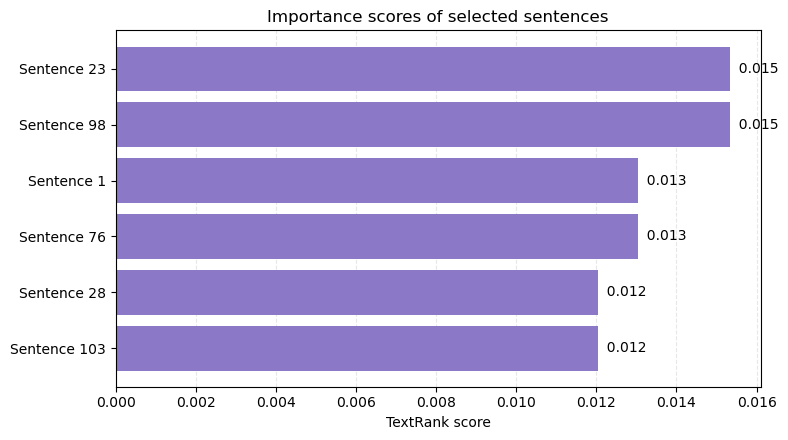

In [9]:
import re
import textwrap
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Get the cleaned text of the first article
first_article = Research_Articles.loc[0, "Article_Content_Cleaned"]

# Split the article into sentences
sentences = [
    sentence.strip()
    for sentence in re.split(r'(?<=[.!?])\s+(?=[A-Z“"(])', first_article)
    if len(sentence.split()) >= 5
]

# Represent the sentences as TF-IDF vectors and calculate their similarity
vectorizer = TfidfVectorizer(stop_words="english")
sentence_vectors = vectorizer.fit_transform(sentences)
similarity_matrix = cosine_similarity(sentence_vectors)

# Remove self-similarity and calculate TextRank scores
np.fill_diagonal(similarity_matrix, 0)

row_sums = similarity_matrix.sum(axis=1, keepdims=True)
transition_matrix = np.divide(
    similarity_matrix,
    row_sums,
    out=np.zeros_like(similarity_matrix),
    where=row_sums != 0
)

# Give unconnected sentences equal transition probabilities
unconnected = row_sums.ravel() == 0
transition_matrix[unconnected, :] = 1 / len(sentences)

scores = np.ones(len(sentences)) / len(sentences)
damping = 0.85

for _ in range(100):
    updated_scores = (
        (1 - damping) / len(sentences)
        + damping * transition_matrix.T.dot(scores)
    )

    if np.allclose(updated_scores, scores):
        scores = updated_scores
        break

    scores = updated_scores

# Select the six highest-ranked sentences and keep their original order
number_to_select = min(6, len(sentences))
selected_indices = np.argsort(scores)[-number_to_select:]
selected_indices = sorted(selected_indices)

print("TextRank summary of the first article:\n")

for index in selected_indices:
    print(f"• {sentences[index]}\n")

# Plot the scores of the selected sentences using short labels
chart_indices = sorted(
    selected_indices,
    key=lambda index: scores[index],
    reverse=True
)

sentence_labels = [
    f"Sentence {index + 1}"
    for index in chart_indices
]
sentence_scores = [scores[index] for index in chart_indices]

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.barh(
    sentence_labels,
    sentence_scores,
    color="#8B78C6"
)

ax.invert_yaxis()
ax.set_xlabel("TextRank score")
ax.set_title("Importance scores of selected sentences")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

for bar, score in zip(bars, sentence_scores):
    ax.text(
        score,
        bar.get_y() + bar.get_height() / 2,
        f"  {score:.3f}",
        va="center"
    )

plt.tight_layout()
plt.show()

The chart shows the six selected sentences ranked by TextRank score. Sentences 23 and 98 received the highest scores (approximately 0.015), indicating that they were the most connected to the other sentences in the article. These scores represent relative sentence importance within this article.

# Question 3.4 : Aggregate summary of the remaining articles

The remaining four articles were summarised together using Maximal Marginal Relevance (MMR). TF-IDF was used to represent the articles and their sentences. MMR selected sentences that were relevant to the collection while reducing repetition. Up to two sentences were selected from each article to give all four articles a voice in the aggregate summary (Carbonell and Goldstein, 1998).

The first visualisation compares the MMR scores of the selected sentences. The second shows the lexical similarity between the articles, based on their TF-IDF representations.

Aggregate summary of Articles 2–5:

research_2.txt — Sentence 3: Benefits and challenges to reflexivity under three types of researcher’s position are discussed and illustrated by means of case examples: (1) reflexivity when researcher shares the experience of study participants, (2) reflexivity when researcher moves from the position of an outsider to the position of an insider in the course of the study, and (3) reflexivity when researcher has no personal familiarity or experience with what is being studied.

research_2.txt — Sentence 7: Reflexivity has been increasingly recognized as a crucial strategy in the process of generating knowledge by means of qualitative research (Ahmed Dunya et al., 2011; Blaxter et al., 2006; D’Cruz et al., 2007; Gerstl-Pepin and Patrizion, 2009; Hammersley and Atkinson, 2002; Horsburgh, 2003; Koch and Harrington, 1998).For example, the journal Forum: Qualitative Research dedicated a full issue (May 2003) to subjectivity and reflexivity in qualitative re

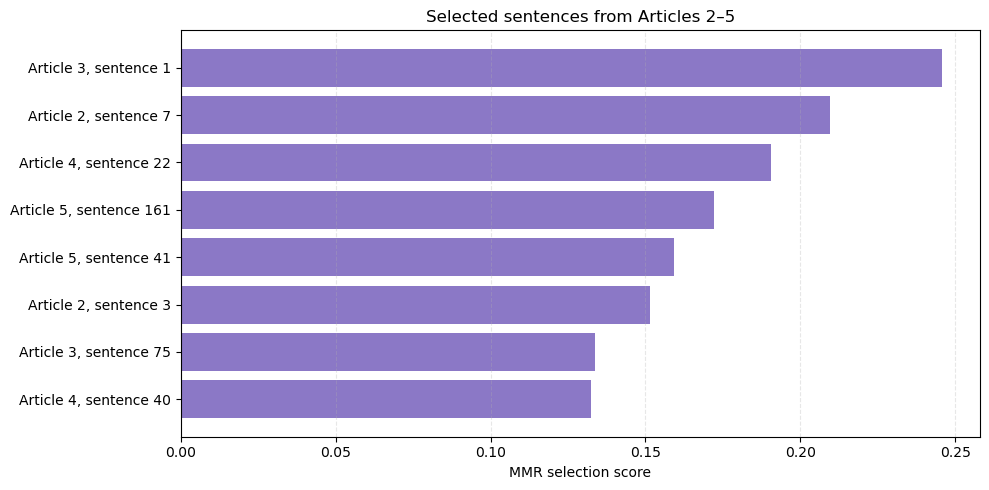

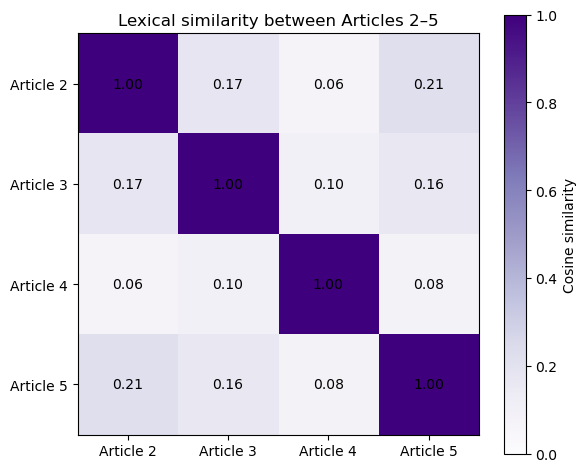

In [10]:
import re
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Use Articles 2–5 because Article 1 was summarised in Question 3.3
remaining_articles = Research_Articles.iloc[1:].copy()

# Split the remaining articles into sentences
sentence_records = []

for _, article in remaining_articles.iterrows():
    article_sentences = re.split(
        r'(?<=[.!?])\s+(?=[A-Z“"(])',
        article["Article_Content_Cleaned"]
    )

    for sentence_number, sentence in enumerate(article_sentences, start=1):
        sentence = sentence.strip()

        if len(sentence.split()) >= 5:
            sentence_records.append({
                "Article_ID": article["Article_ID"],
                "File_Name": article["File_Name"],
                "Sentence_Number": sentence_number,
                "Sentence": sentence
            })

# Create TF-IDF representations of the articles and sentences
vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_features=3000
)

article_vectors = vectorizer.fit_transform(
    remaining_articles["Article_Content_Cleaned"]
)

sentence_vectors = vectorizer.transform(
    [record["Sentence"] for record in sentence_records]
)

# Score how relevant each sentence is to the remaining article collection
corpus_centroid = np.asarray(article_vectors.mean(axis=0))
relevance_scores = cosine_similarity(
    sentence_vectors,
    corpus_centroid
).ravel()

# Calculate sentence similarities 
sentence_similarity = cosine_similarity(sentence_vectors)

# Select up to two sentences from each article
selected_indices = []
selected_mmr_scores = {}

article_counts = {
    article_id: 0
    for article_id in remaining_articles["Article_ID"]
}

summary_size = min(8, len(sentence_records))
max_sentences_per_article = 2
relevance_weight = 0.7

for _ in range(summary_size):
    available_indices = [
        index
        for index, record in enumerate(sentence_records)
        if index not in selected_indices
        and article_counts[record["Article_ID"]] < max_sentences_per_article
    ]

    if not available_indices:
        break

    if selected_indices:
        redundancy_scores = sentence_similarity[
            np.ix_(available_indices, selected_indices)
        ].max(axis=1)
    else:
        redundancy_scores = np.zeros(len(available_indices))

    mmr_scores = (
        relevance_weight * relevance_scores[available_indices]
        - (1 - relevance_weight) * redundancy_scores
    )

    best_position = np.argmax(mmr_scores)
    best_index = available_indices[best_position]

    selected_indices.append(best_index)
    selected_mmr_scores[best_index] = mmr_scores[best_position]
    article_counts[sentence_records[best_index]["Article_ID"]] += 1

# Print the aggregate summary in article order
selected_sentences = sorted(
    [sentence_records[index] for index in selected_indices],
    key=lambda record: (
        record["Article_ID"],
        record["Sentence_Number"]
    )
)

print("Aggregate summary of Articles 2–5:\n")

for record in selected_sentences:
    print(
        f"{record['File_Name']} — "
        f"Sentence {record['Sentence_Number']}: "
        f"{record['Sentence']}\n"
    )

# Chart 1: actual MMR scores of the selected sentences
ranked_indices = sorted(
    selected_indices,
    key=lambda index: selected_mmr_scores[index],
    reverse=True
)

sentence_labels = [
    f"Article {sentence_records[index]['Article_ID']}, "
    f"sentence {sentence_records[index]['Sentence_Number']}"
    for index in ranked_indices
]

selected_scores = [
    selected_mmr_scores[index]
    for index in ranked_indices
]

plt.figure(figsize=(10, 5))
plt.barh(sentence_labels, selected_scores, color="#8B78C6")
plt.gca().invert_yaxis()
plt.xlabel("MMR selection score")
plt.title("Selected sentences from Articles 2–5")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# Chart 2: lexical similarity between the four articles
article_similarity = cosine_similarity(article_vectors)

article_labels = [
    f"Article {article_id}"
    for article_id in remaining_articles["Article_ID"]
]

fig, ax = plt.subplots(figsize=(6, 5))
heatmap = ax.imshow(
    article_similarity,
    cmap="Purples",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(article_labels)), article_labels)
ax.set_yticks(range(len(article_labels)), article_labels)
ax.set_title("Lexical similarity between Articles 2–5")

for row in range(len(article_labels)):
    for column in range(len(article_labels)):
        ax.text(
            column,
            row,
            f"{article_similarity[row, column]:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(heatmap, ax=ax, label="Cosine similarity")
plt.tight_layout()
plt.show()

The selected sentences represent all four remaining articles while limiting the number of sentences selected from each article. The heatmap shows low lexical similarity overall. Articles 2 and 5 have the highest shared-word similarity (0.21), while Articles 2 and 4 have the lowest (0.06). This suggests the articles cover different subject areas. As the corpus contains only four articles, these findings should be treated as exploratory.

# Question 4.1: Topic modelling using Latent Dirichlet Allocation

Latent Dirichlet Allocation (LDA) was applied to all five articles. I selected three topics to provide a broad, exploratory view of the small corpus. The top words for each topic are displayed, along with the proportion of each topic in each article. The visualisations show the most prominent words per topic and the topic distribution across the articles (Blei, Ng and Jordan, 2003).

Topic 1: research, methods, qualitative, mixed, researchers, researcher, quantitative, methods research, mixed methods, data
Topic 2: alpha, cronbach, instrument, cronbach alpha, science, reliability, values, items, education, authors
Topic 3: research, data, development, triangulation, design, study, developmental, process, developmental research, instructional


,File_Name,Topic 1,Topic 2,Topic 3
0,research_1.txt,1.000,0.0,0.0
1,research_2.txt,0.999,0.0,0.0
2,research_3.txt,0.000,0.0,1.0
3,research_4.txt,0.000,1.0,0.0
4,research_5.txt,0.000,0.0,1.0


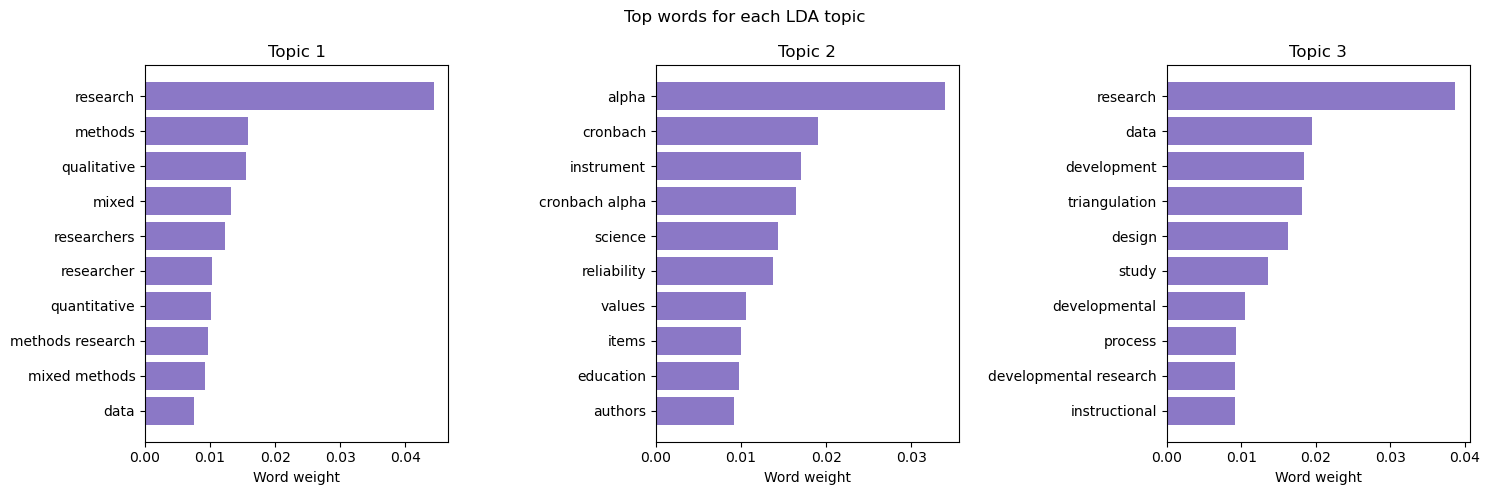

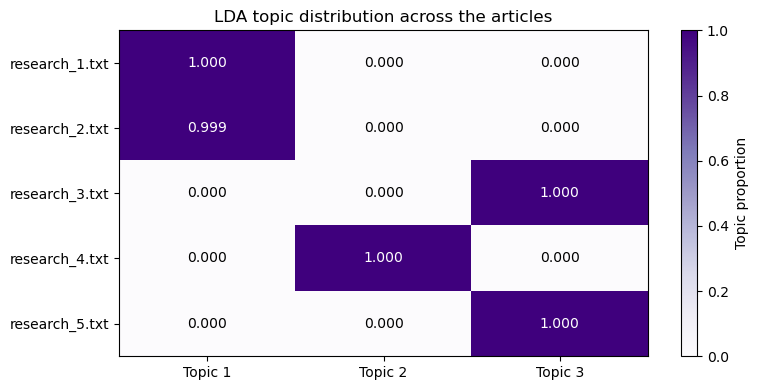

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Use the cleaned text from all 5 articles 
article_texts = Research_Articles['Article_Content_Cleaned']

# Convert the articles text into word count data for the LDA
count_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_features=1500,
    min_df=1,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b"
)

document_term_matrix = count_vectorizer.fit_transform(article_texts)

# Fit the LDA with 3 topics 
number_of_topics = 3

lda_model = LatentDirichletAllocation(
    n_components=number_of_topics,
    random_state=42,
    max_iter = 40,
    learning_method='batch'
)

document_topic_distribution = lda_model.fit_transform(document_term_matrix)
feature_names = count_vectorizer.get_feature_names_out()

# Display the 10 highest weighted words for each topic
topic_word_distribution = (
    lda_model.components_
    / lda_model.components_.sum(axis=1, keepdims=True)
)

top_words_per_topic = {}

for topic_number, topic_weights in enumerate(topic_word_distribution, start=1):
    top_word_indices = topic_weights.argsort()[-10:][::-1]
    top_words = feature_names[top_word_indices]
    top_words_per_topic[f"Topic {topic_number}"] = top_words

    print(f"Topic {topic_number}: {', '.join(top_words)}")

# Display each article's distribution across the three topics
topic_columns = [f"Topic {number}" for number in range(1, number_of_topics + 1)]

topic_distribution_table = pd.DataFrame(
    document_topic_distribution,
    columns=topic_columns
)

topic_distribution_table.insert(
    0,
    "File_Name",
    Research_Articles["File_Name"].to_numpy()
)

display(topic_distribution_table.round(3))

# Visualisation 1: top words in each topic
fig, axes = plt.subplots(1, number_of_topics, figsize=(15, 5))

for topic_index, ax in enumerate(axes):
    topic_weights = topic_word_distribution[topic_index]
    top_word_indices = topic_weights.argsort()[-10:][::-1]

    words = feature_names[top_word_indices][::-1]
    weights = topic_weights[top_word_indices][::-1]

    ax.barh(words, weights, color="#8B78C6")
    ax.set_title(f"Topic {topic_index + 1}")
    ax.set_xlabel("Word weight")

fig.suptitle("Top words for each LDA topic")
plt.tight_layout()
plt.show()

# Visualisation 2: topic proportions in each article
fig, ax = plt.subplots(figsize=(8, 4))

heatmap = ax.imshow(
    document_topic_distribution,
    cmap="Purples",
    vmin=0,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(number_of_topics))
ax.set_xticklabels(
    [f"Topic {number}" for number in range(1, number_of_topics + 1)]
)

ax.set_yticks(range(len(Research_Articles)))
ax.set_yticklabels(Research_Articles["File_Name"])

ax.set_title("LDA topic distribution across the articles")

# Write each topic proportion inside its cell
for row in range(document_topic_distribution.shape[0]):
    for column in range(document_topic_distribution.shape[1]):
        value = document_topic_distribution[row, column]
        text_colour = "white" if value > 0.5 else "black"

        ax.text(
            column,
            row,
            f"{value:.3f}",
            ha="center",
            va="center",
            color=text_colour
        )

fig.colorbar(heatmap, ax=ax, label="Topic proportion")
plt.tight_layout()
plt.show()


My intepretation:

- Topic 1 is mainly associated with research methods, including qualitative, quantitative and mixed-methods research. It is strongest in Articles 1 and 2. Topic 2 is characterized by Cronbach’s alpha, instruments and reliability, and is strongest in Article 4. Topic 3 contains terms related to research design, development and triangulation, and is strongest in Articles 3 and 5.
The topics are exploratory because the corpus contains only five articles. Topic 3 also combines several kinds of terms, so its theme is less clearly defined. The supplied articles focus on research methods and education rather than artificial intelligence, which limits what this corpus can show about AI research trends.


# Question 4.2: pyLDAvis, Intertopic Distance interactive Map

In [16]:
%pip install pyLDAvis

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 3.6 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.4/24.4 MB 11.6 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pyLDAvis]3/4 [pyLDAvis]
Note: you may need to restart the kernel to use updated packages.


In [17]:
import pyLDAvis
import pyLDAvis.lda_model

# Have to prepare the visualisation from fitted LDA model
lda_visualisation = pyLDAvis.lda_model.prepare(
    lda_model,
    document_term_matrix,
    count_vectorizer
)

# Display the interactive map 
pyLDAvis.display(lda_visualisation)

# Save a separate HTML copy that is able to be opened in a browser 
pyLDAvis.save_html(
    lda_visualisation,
    "Q4_2_LDA_intertopic_distance_map.html"
)

In [18]:
from IPython.display import HTML, display

map_html = pyLDAvis.prepared_data_to_html(lda_visualisation)
display(HTML(map_html))